In [1]:
import os
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print(f"🔥 TensorFlow versión: {tf.__version__}")
print(f"🧠 Keras versión:      {keras.__version__}")

# 1. Cargar los conjuntos del Modelo 3 (Notebook 08)
processed_dir = "../data/processed/modelo3"
df_train = pd.read_parquet(os.path.join(processed_dir, "train.parquet"))
df_val   = pd.read_parquet(os.path.join(processed_dir, "val.parquet"))
df_test  = pd.read_parquet(os.path.join(processed_dir, "test.parquet"))

y_train = df_train['accion'].values
y_val   = df_val['accion'].values
y_test  = df_test['accion'].values

print("\n📖 Conjuntos del Modelo 3 cargados (partición cronológica):")
print(f" • Entrenamiento (Train): {len(df_train):,} decisiones")
print(f" • Validación    (Val):   {len(df_val):,} decisiones")
print(f" • Prueba        (Test):  {len(df_test):,} decisiones (las manos más recientes)")

os.makedirs('../informe/figuras', exist_ok=True)
os.makedirs('../informe/metricas', exist_ok=True)
resultados = {}   # aquí se acumulan todas las métricas para el informe

🔥 TensorFlow versión: 2.21.0
🧠 Keras versión:      3.15.1



📖 Conjuntos del Modelo 3 cargados (partición cronológica):
 • Entrenamiento (Train): 2,584,256 decisiones
 • Validación    (Val):   596,389 decisiones
 • Prueba        (Test):  593,212 decisiones (las manos más recientes)


In [2]:
# Grupos de variables: se añaden por bloques para medir cuánto aporta cada uno (ablación)
G0_ORIGINALES = ['calle', 'bote', 'to_call', 'stack', 'pot_odds']                # las 5 del Modelo 2 (fichas)
G1_CIEGAS = ['calle', 'bote_bb', 'to_call_bb', 'stack_bb', 'pot_odds', 'stake_1000']   # mismas, en ciegas grandes
G2_CONTEXTO = G1_CIEGAS + [
    'n_jug', 'n_activos', 'n_allin', 'detras', 'pos_pre', 'pos_post',          # mesa y posición
    'es_sb', 'es_bb', 'es_boton',
    'eff_bb', 'spr', 'call_vs_bote', 'call_es_allin', 'invertido_bb',          # dinero en juego
    'subidas_calle', 'callers_calle', 'checks_calle', 'subidas_pre',           # historial de apuestas
    'ult_apuesta_vs_bote', 'ya_actuo_calle', 'ya_subio_calle',
    'es_agresor_pre', 'es_agresor_prev', 'hay_agresor_prev']
G3_MESA = G2_CONTEXTO + ['b_n', 'b_pareada', 'b_trio', 'b_max_palo', 'b_alta', 'b_broadway', 'b_conect']
G4_PERFIL = G3_MESA + ['pf_manos', 'pf_vpip', 'pf_pfr', 'pf_fold_enf', 'pf_raise_enf', 'pf_bet_libre', 'pf_post_agr']

GRUPOS = {
    'G0 · 5 variables originales (fichas)': G0_ORIGINALES,
    'G1 · + ciegas grandes y nivel': G1_CIEGAS,
    'G2 · + posición e historial de apuestas': G2_CONTEXTO,
    'G3 · + textura de la mesa': G3_MESA,
    'G4 · + perfil del jugador (HUD)': G4_PERFIL,
}
for nombre, cols in GRUPOS.items():
    print(f" • {nombre:<42} ➔ {len(cols):>2} variables")
FEATURES = G4_PERFIL
print(f"\n🎯 Modelo 3 final: {len(FEATURES)} variables públicas (ninguna carta privada)")

 • G0 · 5 variables originales (fichas)       ➔  5 variables
 • G1 · + ciegas grandes y nivel              ➔  6 variables
 • G2 · + posición e historial de apuestas    ➔ 30 variables
 • G3 · + textura de la mesa                  ➔ 37 variables
 • G4 · + perfil del jugador (HUD)            ➔ 44 variables

🎯 Modelo 3 final: 44 variables públicas (ninguna carta privada)


In [3]:
from sklearn.preprocessing import StandardScaler

# Las cantidades de dinero tienen colas muy largas (botes de 1 a 700 ciegas): se comprimen con log(1 + x)
VARIABLES_LOG = ['bote', 'to_call', 'stack', 'bote_bb', 'to_call_bb', 'stack_bb', 'eff_bb', 'spr',
                 'invertido_bb', 'ult_apuesta_vs_bote']

def preparar(df, cols):
    """Selecciona columnas, aplica log a las cantidades de dinero y devuelve float32."""
    X = df[cols].copy()
    for c in VARIABLES_LOG:
        if c in X.columns:
            X[c] = np.log1p(X[c].clip(lower=0))
    return X.values.astype('float32')

# REGLA METODOLÓGICA: el escalador se ajusta SOLO con Train
scaler = StandardScaler().fit(preparar(df_train, FEATURES))
X_train = scaler.transform(preparar(df_train, FEATURES))
X_val   = scaler.transform(preparar(df_val, FEATURES))
X_test  = scaler.transform(preparar(df_test, FEATURES))

print("=" * 65)
print("  ESCALADO DE VARIABLES COMPLETADO (Doc. Maestro § 8.2)")
print("=" * 65)
print(f" • Dimensión de X_train: {X_train.shape}")
print(f" • Dimensión de X_val:   {X_val.shape}")
print(f" • Dimensión de X_test:  {X_test.shape}")
print(f" • Media de X_train tras escalar ≈ {X_train.mean():.3f} | Desviación ≈ {X_train.std():.3f}")

  ESCALADO DE VARIABLES COMPLETADO (Doc. Maestro § 8.2)
 • Dimensión de X_train: (2584256, 44)
 • Dimensión de X_val:   (596389, 44)
 • Dimensión de X_test:  (593212, 44)


 • Media de X_train tras escalar ≈ -0.000 | Desviación ≈ 1.000


In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss

def evaluar(nombre, probabilidades):
    """Métricas oficiales sobre Test: exactitud, F1 macro y pérdida logarítmica."""
    pred = probabilidades.argmax(axis=1)
    fila = {
        'accuracy': round(float(accuracy_score(y_test, pred)), 4),
        'f1_macro': round(float(f1_score(y_test, pred, average='macro')), 4),
        'log_loss': round(float(log_loss(y_test, np.clip(probabilidades, 1e-7, 1), labels=[0, 1, 2])), 4),
    }
    resultados[nombre] = fila
    print(f" • {nombre:<46} Accuracy={fila['accuracy'] * 100:.2f}%  F1-Macro={fila['f1_macro']:.3f}  LogLoss={fila['log_loss']:.3f}")
    return pred

print("📏 BASELINES DEL MODELO 3 (mismos datos y misma partición):\n")
# 1. Baseline 1: clase mayoritaria
dummy = DummyClassifier(strategy='most_frequent').fit(df_train[G0_ORIGINALES], y_train)
evaluar('Baseline 1: Clase Mayoritaria (Fold)', dummy.predict_proba(df_test[G0_ORIGINALES]))

# 2. Baseline 2: árbol de 3 niveles con las 5 variables originales (igual que el Notebook 06)
arbol = DecisionTreeClassifier(max_depth=3, random_state=42).fit(df_train[G0_ORIGINALES], y_train)
evaluar('Baseline 2: Árbol Prof. 3 (5 variables)', arbol.predict_proba(df_test[G0_ORIGINALES]))

# 3. Referencia clásica fuerte: Gradient Boosting con las mismas 44 variables de la red
t0 = time.time()
gbm = HistGradientBoostingClassifier(max_iter=600, learning_rate=0.1, max_leaf_nodes=127,
                                     early_stopping=True, validation_fraction=0.1, random_state=0)
gbm.fit(df_train[FEATURES], y_train)
evaluar('Referencia: Gradient Boosting (44 variables)', gbm.predict_proba(df_test[FEATURES]))
print(f"\n⏱️ Gradient Boosting entrenado en {time.time() - t0:.0f} s ({gbm.n_iter_} árboles)")

📏 BASELINES DEL MODELO 3 (mismos datos y misma partición):



C:\Users\lucas\miniconda3\envs\ia_local\Lib\site-packages\sklearn\metrics\_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


 • Baseline 1: Clase Mayoritaria (Fold)           Accuracy=53.76%  F1-Macro=0.233  LogLoss=7.453


 • Baseline 2: Árbol Prof. 3 (5 variables)        Accuracy=69.50%  F1-Macro=0.474  LogLoss=0.737


 • Referencia: Gradient Boosting (44 variables)   Accuracy=73.71%  F1-Macro=0.628  LogLoss=0.616

⏱️ Gradient Boosting entrenado en 117 s (80 árboles)


C:\Users\lucas\miniconda3\envs\ia_local\Lib\site-packages\sklearn\metrics\_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


In [5]:
def crear_red(n_entradas, nombre="PHT_T_Modelo3"):
    """MLP piramidal (256 ➔ 128 ➔ 64 ➔ 3), versión ampliada de la red del Notebook 07."""
    modelo = keras.Sequential([
        layers.Input(shape=(n_entradas,), name="Entrada_Variables"),
        layers.Dense(256, activation='relu', name="Capa_Densa_256"),
        layers.BatchNormalization(name="Normalizacion_1"),
        layers.Dropout(0.2, name="Dropout_20pct_1"),
        layers.Dense(128, activation='relu', name="Capa_Densa_128"),
        layers.BatchNormalization(name="Normalizacion_2"),
        layers.Dropout(0.2, name="Dropout_20pct_2"),
        layers.Dense(64, activation='relu', name="Capa_Densa_64"),
        layers.Dense(3, activation='softmax', name="Salida_Probabilidades")
    ], name=nombre)
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return modelo

def guardianes():
    """Callbacks contra el sobreajuste (igual criterio que el Notebook 07)."""
    return [keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5)]

tf.random.set_seed(42)
modelo = crear_red(X_train.shape[1])
print("=" * 65)
print("  ARQUITECTURA DE LA RED NEURONAL — MODELO 3")
print("=" * 65)
modelo.summary()

  ARQUITECTURA DE LA RED NEURONAL — MODELO 3


Model: "PHT_T_Modelo3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Capa_Densa_256 (Dense)          │ (None, 256)            │        11,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Normalizacion_1                 │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_20pct_1 (Dropout)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Capa_Densa_128 (Dense)          │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Normalizacion_2                 │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_20pct_2 (Dropout)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Capa_Densa_64 (Dense)           │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Salida_Probabilidades (Dense)   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,403 (212.51 KB)

 Trainable params: 53,635 (209.51 KB)

 Non-trainable params: 768 (3.00 KB)

In [6]:
print("🚀 INICIANDO EL ENTRENAMIENTO DEL MODELO 3...")
print(f" • Datos de Entrenamiento: {len(X_train):,} decisiones")
print(f" • Datos de Validación:    {len(X_val):,} decisiones")
print(" • Tamaño del lote (Batch): 1024 | Épocas máximas: 40 (parada automática)\n")

t0 = time.time()
history = modelo.fit(X_train, y_train, validation_data=(X_val, y_val),
                     epochs=40, batch_size=1024, callbacks=guardianes(), verbose=2)
print(f"\n✅ ¡ENTRENAMIENTO COMPLETADO en {time.time() - t0:.0f} s ({len(history.history['loss'])} épocas)!")

🚀 INICIANDO EL ENTRENAMIENTO DEL MODELO 3...
 • Datos de Entrenamiento: 2,584,256 decisiones
 • Datos de Validación:    596,389 decisiones
 • Tamaño del lote (Batch): 1024 | Épocas máximas: 40 (parada automática)



Epoch 1/40


2524/2524 - 39s - 15ms/step - accuracy: 0.7252 - loss: 0.6383 - val_accuracy: 0.7311 - val_loss: 0.6245 - learning_rate: 0.0010


Epoch 2/40


2524/2524 - 28s - 11ms/step - accuracy: 0.7294 - loss: 0.6279 - val_accuracy: 0.7319 - val_loss: 0.6229 - learning_rate: 0.0010


Epoch 3/40


... (72 outputs left out)

2524/2524 - 28s - 11ms/step - accuracy: 0.7340 - loss: 0.6180 - val_accuracy: 0.7345 - val_loss: 0.6170 - learning_rate: 1.0000e-05


Epoch 40/40


2524/2524 - 29s - 11ms/step - accuracy: 0.7339 - loss: 0.6181 - val_accuracy: 0.7345 - val_loss: 0.6170 - learning_rate: 1.0000e-05



✅ ¡ENTRENAMIENTO COMPLETADO en 1236 s (40 épocas)!


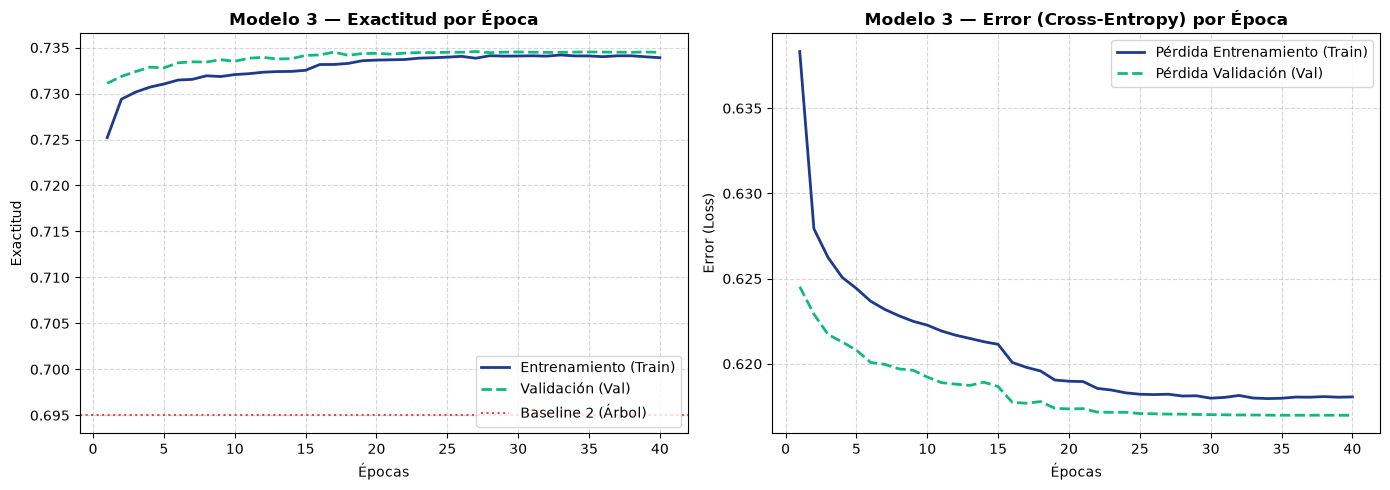

🎯 Mejor exactitud en Validación: 73.46%
📉 Menor pérdida en Validación:   0.6170
📏 Brecha Train - Val (última época): -0.06 puntos ➔ sin sobreajuste


In [7]:
acc, val_acc = history.history['accuracy'], history.history['val_accuracy']
loss, val_loss = history.history['loss'], history.history['val_loss']
epocas = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epocas, acc, label='Entrenamiento (Train)', color='#1e3a8a', linewidth=2)
plt.plot(epocas, val_acc, label='Validación (Val)', color='#10b981', linewidth=2, linestyle='--')
plt.axhline(y=resultados['Baseline 2: Árbol Prof. 3 (5 variables)']['accuracy'], color='#ef4444', linestyle=':',
            label='Baseline 2 (Árbol)')
plt.title('Modelo 3 — Exactitud por Época', fontsize=12, fontweight='bold')
plt.xlabel('Épocas'); plt.ylabel('Exactitud'); plt.legend(loc='lower right'); plt.grid(True, linestyle='--', alpha=0.5)
plt.subplot(1, 2, 2)
plt.plot(epocas, loss, label='Pérdida Entrenamiento (Train)', color='#1e3a8a', linewidth=2)
plt.plot(epocas, val_loss, label='Pérdida Validación (Val)', color='#10b981', linewidth=2, linestyle='--')
plt.title('Modelo 3 — Error (Cross-Entropy) por Época', fontsize=12, fontweight='bold')
plt.xlabel('Épocas'); plt.ylabel('Error (Loss)'); plt.legend(loc='upper right'); plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('../informe/figuras/modelo3_curvas_aprendizaje.png', dpi=150, bbox_inches='tight')
plt.show()

print("=" * 65)
print(f"🎯 Mejor exactitud en Validación: {max(val_acc) * 100:.2f}%")
print(f"📉 Menor pérdida en Validación:   {min(val_loss):.4f}")
print(f"📏 Brecha Train - Val (última época): {(acc[-1] - val_acc[-1]) * 100:.2f} puntos ➔ {'sin sobreajuste' if abs(acc[-1] - val_acc[-1]) < 0.02 else 'revisar sobreajuste'}")
print("=" * 65)

🎓 APLICANDO EL EXAMEN FINAL EN TEST (593,212 decisiones de los últimos días)...



 • 🎯 Red Neuronal MLP — Modelo 3 (44 variables)   Accuracy=73.83%  F1-Macro=0.630  LogLoss=0.612

📋 REPORTE DE CLASIFICACIÓN DETALLADO:
                precision    recall  f1-score   support

      Fold (0)     0.7625    0.9474    0.8449    318895
Check/Call (1)     0.7060    0.6234    0.6621    173810
 Bet/Raise (2)     0.6322    0.2737    0.3821    100507

      accuracy                         0.7383    593212
     macro avg     0.7002    0.6148    0.6297    593212
  weighted avg     0.7239    0.7383    0.7129    593212



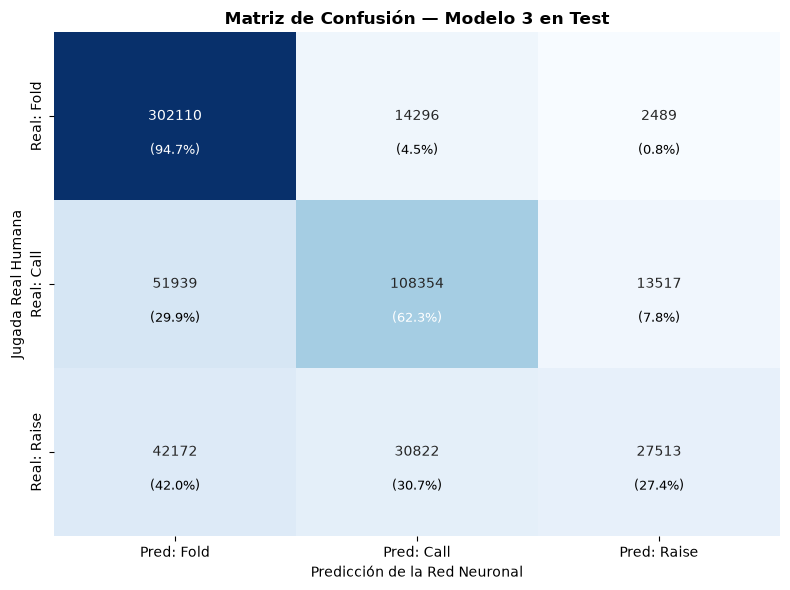

In [8]:
from sklearn.metrics import classification_report, confusion_matrix

print(f"🎓 APLICANDO EL EXAMEN FINAL EN TEST ({len(y_test):,} decisiones de los últimos días)...\n")
prob_test = modelo.predict(X_test, batch_size=4096, verbose=0)
y_pred = evaluar('🎯 Red Neuronal MLP — Modelo 3 (44 variables)', prob_test)

nombres_clases = ['Fold (0)', 'Check/Call (1)', 'Bet/Raise (2)']
print("\n📋 REPORTE DE CLASIFICACIÓN DETALLADO:")
print(classification_report(y_test, y_pred, target_names=nombres_clases, digits=4))

cm = confusion_matrix(y_test, y_pred)
cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Pred: Fold', 'Pred: Call', 'Pred: Raise'],
            yticklabels=['Real: Fold', 'Real: Call', 'Real: Raise'])
for i in range(3):
    for j in range(3):
        color_texto = 'white' if cm[i, j] > (len(y_test) / 6) else 'black'
        plt.text(j + 0.5, i + 0.7, f"({cm_pct[i, j]:.1f}%)", ha="center", va="center", color=color_texto, fontsize=9)
plt.title('Matriz de Confusión — Modelo 3 en Test', fontsize=12, fontweight='bold')
plt.ylabel('Jugada Real Humana'); plt.xlabel('Predicción de la Red Neuronal')
plt.tight_layout()
plt.savefig('../informe/figuras/modelo3_matriz_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

reporte_clases_m3 = classification_report(y_test, y_pred, target_names=nombres_clases, output_dict=True)

🧪 ABLACIÓN: misma red, añadiendo grupos de variables uno a uno



 • Ablación G0 · 5 variables originales (fichas)  Accuracy=70.19%  F1-Macro=0.507  LogLoss=0.696


 • Ablación G1 · + ciegas grandes y nivel         Accuracy=70.20%  F1-Macro=0.510  LogLoss=0.696


 • Ablación G2 · + posición e historial de apuestas Accuracy=72.73%  F1-Macro=0.612  LogLoss=0.657


 • Ablación G3 · + textura de la mesa             Accuracy=72.77%  F1-Macro=0.614  LogLoss=0.657
 • Ablación G4 · + perfil del jugador (HUD)       Accuracy=73.83%  F1-Macro=0.630  LogLoss=0.612


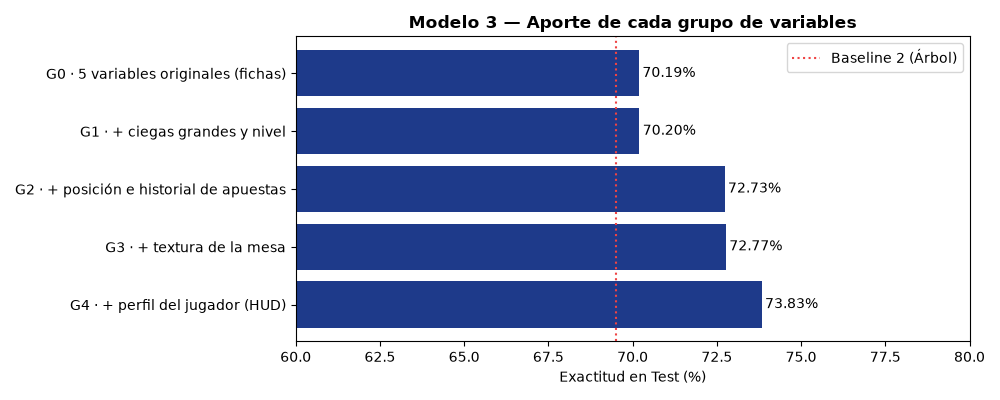

In [9]:
# EXPERIMENTO 1 — ABLACIÓN: ¿cuánto aporta cada grupo de variables a la red?
print("🧪 ABLACIÓN: misma red, añadiendo grupos de variables uno a uno\n")
predicciones_grupo = {}
for nombre, cols in GRUPOS.items():
    if cols is FEATURES:
        prob = prob_test   # el modelo completo ya está entrenado
    else:
        esc = StandardScaler().fit(preparar(df_train, cols))
        tf.random.set_seed(42)
        red = crear_red(len(cols), nombre="Ablacion")
        red.fit(esc.transform(preparar(df_train, cols)), y_train,
                validation_data=(esc.transform(preparar(df_val, cols)), y_val),
                epochs=40, batch_size=1024, callbacks=guardianes(), verbose=0)
        prob = red.predict(esc.transform(preparar(df_test, cols)), batch_size=4096, verbose=0)
    predicciones_grupo[nombre] = prob.argmax(axis=1)
    evaluar(f"Ablación {nombre}", prob)

ablacion = pd.DataFrame({k.replace('Ablación ', ''): v for k, v in resultados.items() if k.startswith('Ablación')}).T
plt.figure(figsize=(10, 4))
plt.barh(ablacion.index[::-1], ablacion['accuracy'][::-1] * 100, color='#1e3a8a')
plt.axvline(resultados['Baseline 2: Árbol Prof. 3 (5 variables)']['accuracy'] * 100, color='#ef4444', linestyle=':', label='Baseline 2 (Árbol)')
for i, v in enumerate(ablacion['accuracy'][::-1] * 100):
    plt.text(v + 0.1, i, f"{v:.2f}%", va='center')
plt.xlim(60, 80); plt.xlabel('Exactitud en Test (%)'); plt.legend(loc='upper right')
plt.title('Modelo 3 — Aporte de cada grupo de variables', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../informe/figuras/modelo3_ablacion.png', dpi=150, bbox_inches='tight')
plt.show()

📈 CURVA DE APRENDIZAJE: misma red, entrenada con más o menos decisiones



 •     50,000 decisiones ➔ Accuracy en Test: 73.14%


 •    200,000 decisiones ➔ Accuracy en Test: 73.53%


 •    800,000 decisiones ➔ Accuracy en Test: 73.75%
 •  2,584,256 decisiones ➔ Accuracy en Test: 73.83%


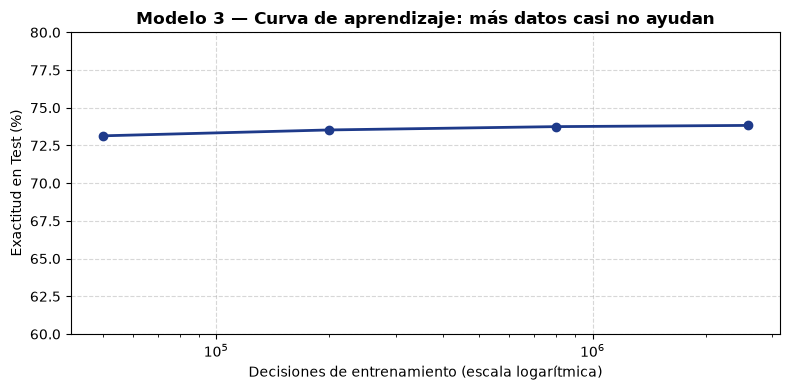

In [10]:
# EXPERIMENTO 2 — CURVA DE APRENDIZAJE: ¿más datos mejoran la red?
print("📈 CURVA DE APRENDIZAJE: misma red, entrenada con más o menos decisiones\n")
tamanos = [50_000, 200_000, 800_000, len(X_train)]
curva = []
rng = np.random.default_rng(0)
for n in tamanos:
    idx = rng.choice(len(X_train), size=n, replace=False) if n < len(X_train) else np.arange(len(X_train))
    if n == len(X_train):
        prob = prob_test
    else:
        tf.random.set_seed(42)
        red = crear_red(X_train.shape[1], nombre="Curva")
        red.fit(X_train[idx], y_train[idx], validation_data=(X_val, y_val),
                epochs=40, batch_size=1024, callbacks=guardianes(), verbose=0)
        prob = red.predict(X_test, batch_size=4096, verbose=0)
    acc_n = accuracy_score(y_test, prob.argmax(axis=1))
    curva.append({'decisiones_entrenamiento': int(n), 'accuracy': round(float(acc_n), 4)})
    print(f" • {n:>10,} decisiones ➔ Accuracy en Test: {acc_n * 100:.2f}%")

curva = pd.DataFrame(curva)
plt.figure(figsize=(8, 4))
plt.plot(curva['decisiones_entrenamiento'], curva['accuracy'] * 100, marker='o', color='#1e3a8a', linewidth=2)
plt.xscale('log'); plt.ylim(60, 80); plt.grid(True, linestyle='--', alpha=0.5)
plt.xlabel('Decisiones de entrenamiento (escala logarítmica)'); plt.ylabel('Exactitud en Test (%)')
plt.title('Modelo 3 — Curva de aprendizaje: más datos casi no ayudan', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../informe/figuras/modelo3_curva_datos.png', dpi=150, bbox_inches='tight')
plt.show()

1. EXACTITUD POR SITUACIÓN DE JUEGO:
                            decisiones  exactitud  % del test
situacion                                                    
Postflop, enfrenta apuesta       65802      62.57       11.09
Postflop, nadie apostó          123077      71.20       20.75
Preflop, enfrenta subida        140529      80.17       23.69
Preflop, nadie ha subido        263804      74.49       44.47

2. EXACTITUD SEGÚN EL HISTORIAL PREVIO DEL JUGADOR (con y sin variables de perfil):
           decisiones  sin_perfil  con_perfil
historial                                    
0 manos          6430       60.22       63.39
1-20            86096       64.47       65.96
21-100         138687       66.40       68.01
101-500        172725       73.72       74.72
>500           189274       80.77       81.22

3. CALIBRACIÓN DE LAS PROBABILIDADES:
             decisiones  confianza_media  exactitud_real
tramo                                                   
(0.33, 0.5]       33416        

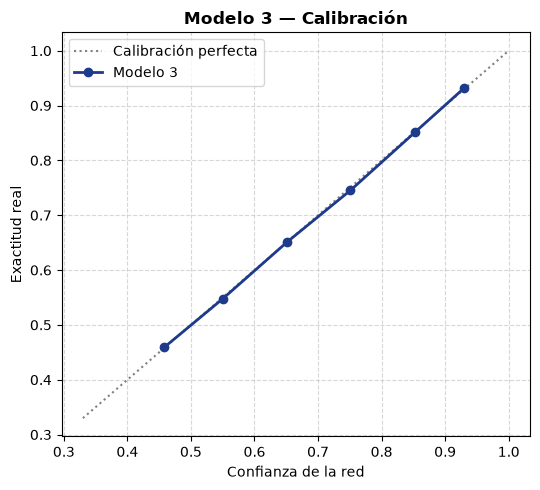

In [11]:
# EXPERIMENTO 3 — ¿DÓNDE ACIERTA Y DÓNDE FALLA LA RED?
analisis = df_test[['calle', 'subidas_calle', 'to_call', 'pf_manos', 'accion']].copy()
analisis['acierto'] = (y_pred == y_test)
analisis['confianza'] = prob_test.max(axis=1)
analisis['situacion'] = np.select(
    [(analisis['calle'] == 0) & (analisis['subidas_calle'] == 0),
     (analisis['calle'] == 0) & (analisis['subidas_calle'] > 0),
     (analisis['calle'] > 0) & (analisis['to_call'] == 0),
     (analisis['calle'] > 0) & (analisis['to_call'] > 0)],
    ['Preflop, nadie ha subido', 'Preflop, enfrenta subida', 'Postflop, nadie apostó', 'Postflop, enfrenta apuesta'],
    default='Otra')

print("1. EXACTITUD POR SITUACIÓN DE JUEGO:")
por_situacion = analisis.groupby('situacion').agg(decisiones=('acierto', 'size'), exactitud=('acierto', 'mean'))
por_situacion['% del test'] = por_situacion['decisiones'] / len(analisis) * 100
print((por_situacion.assign(exactitud=lambda t: t['exactitud'] * 100)).round(2).to_string())

# 2. ¿El perfil del jugador explica la mejora con jugadores conocidos? (control de confusión)
analisis['historial'] = pd.cut(np.expm1(analisis['pf_manos']), [-1, 0, 20, 100, 500, 1e9],
                               labels=['0 manos', '1-20', '21-100', '101-500', '>500'])
analisis['acierto_sin_perfil'] = (predicciones_grupo['G3 · + textura de la mesa'] == y_test)
print("\n2. EXACTITUD SEGÚN EL HISTORIAL PREVIO DEL JUGADOR (con y sin variables de perfil):")
por_historial = analisis.groupby('historial', observed=True).agg(
    decisiones=('acierto', 'size'), sin_perfil=('acierto_sin_perfil', 'mean'), con_perfil=('acierto', 'mean'))
print((por_historial.assign(sin_perfil=lambda t: t['sin_perfil'] * 100, con_perfil=lambda t: t['con_perfil'] * 100)).round(2).to_string())

# 3. Calibración: cuando la red dice "80% seguro", ¿acierta el 80% de las veces?
analisis['tramo'] = pd.cut(analisis['confianza'], [0.33, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
calibracion = analisis.groupby('tramo', observed=True).agg(
    decisiones=('acierto', 'size'), confianza_media=('confianza', 'mean'), exactitud_real=('acierto', 'mean'))
print("\n3. CALIBRACIÓN DE LAS PROBABILIDADES:")
print(calibracion.round(3).to_string())

plt.figure(figsize=(5.5, 5))
plt.plot([0.33, 1], [0.33, 1], linestyle=':', color='gray', label='Calibración perfecta')
plt.plot(calibracion['confianza_media'], calibracion['exactitud_real'], marker='o', color='#1e3a8a', linewidth=2, label='Modelo 3')
plt.xlabel('Confianza de la red'); plt.ylabel('Exactitud real'); plt.legend(); plt.grid(True, linestyle='--', alpha=0.5)
plt.title('Modelo 3 — Calibración', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../informe/figuras/modelo3_calibracion.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
import joblib

# 1. Guardar la red, el escalador y la lista exacta de variables (necesaria para la aplicación)
models_dir = "../models/v3_45_variables"
os.makedirs(models_dir, exist_ok=True)
model_file = os.path.join(models_dir, "pht_t_modelo3.keras")
scaler_file = os.path.join(models_dir, "scaler_modelo3.pkl")
features_file = os.path.join(models_dir, "variables_modelo3.json")

print("💾 Guardando el Modelo 3 en models/v3_45_variables/...")
modelo.save(model_file)
joblib.dump(scaler, scaler_file)
with open(features_file, 'w', encoding='utf-8') as f:
    json.dump({'features': FEATURES, 'variables_log': VARIABLES_LOG}, f, ensure_ascii=False, indent=2)

print("\n✅ ¡ARTEFACTOS GUARDADOS CON ÉXITO!")
print(f" • Red Neuronal: {model_file} ➔ ({os.path.getsize(model_file) / 1024:.1f} KB)")
print(f" • Escalador:    {scaler_file} ➔ ({os.path.getsize(scaler_file) / 1024:.1f} KB)")
print(f" • Variables:    {features_file}")

# 2. Prueba de cordura: cargar desde disco y comparar con el modelo en memoria
modelo_cargado = keras.models.load_model(model_file)
scaler_cargado = joblib.load(scaler_file)
prob_cargado = modelo_cargado.predict(scaler_cargado.transform(preparar(df_test.head(1000), FEATURES)), verbose=0)
print(f"\n🧪 Diferencia máxima entre el modelo en memoria y el cargado (1.000 decisiones): {np.abs(prob_cargado - prob_test[:1000]).max():.2e}")

💾 Guardando el Modelo 3 en models/v3_45_variables/...

✅ ¡ARTEFACTOS GUARDADOS CON ÉXITO!
 • Red Neuronal: ../models/v3_45_variables\pht_t_modelo3.keras ➔ (677.4 KB)
 • Escalador:    ../models/v3_45_variables\scaler_modelo3.pkl ➔ (1.6 KB)
 • Variables:    ../models/v3_45_variables\variables_modelo3.json



🧪 Diferencia máxima entre el modelo en memoria y el cargado (1.000 decisiones): 2.38e-07


In [13]:
# Tabla final y exportación de métricas para el informe académico
tabla = pd.DataFrame(resultados).T
tabla['accuracy'] = (tabla['accuracy'] * 100).map(lambda v: f"{v:.2f}%")
print("=" * 95)
print("  TABLA COMPARATIVA FINAL — MODELO 3 (Test cronológico)")
print("=" * 95)
print(tabla.to_string())
print("=" * 95)

metricas_m3 = {
    "modelo": "Modelo 3 - MLP 44 variables públicas, shard completo, partición cronológica",
    "n_train": int(len(y_train)), "n_val": int(len(y_val)), "n_test": int(len(y_test)),
    "resultados": resultados,
    "reporte_por_clase": reporte_clases_m3,
    "matriz_confusion": cm.tolist(),
    "curva_aprendizaje": curva.to_dict(orient='records'),
    "por_situacion": por_situacion.reset_index().to_dict(orient='records'),
    "por_historial": por_historial.reset_index().astype({'historial': str}).to_dict(orient='records'),
    "calibracion": calibracion.reset_index().astype({'tramo': str}).to_dict(orient='records'),
    "epocas": len(history.history['loss']),
}
with open('../informe/metricas/modelo3.json', 'w', encoding='utf-8') as f:
    json.dump(metricas_m3, f, ensure_ascii=False, indent=2, default=float)
print("\n💾 Métricas guardadas en informe/metricas/modelo3.json")
print("🎉 ¡Modelo 3 completado!")

  TABLA COMPARATIVA FINAL — MODELO 3 (Test cronológico)
                                                 accuracy  f1_macro  log_loss
Baseline 1: Clase Mayoritaria (Fold)               53.76%    0.2331    7.4534
Baseline 2: Árbol Prof. 3 (5 variables)            69.50%    0.4741    0.7366
Referencia: Gradient Boosting (44 variables)       73.71%    0.6278    0.6158
🎯 Red Neuronal MLP — Modelo 3 (44 variables)       73.83%    0.6297    0.6124
Ablación G0 · 5 variables originales (fichas)      70.19%    0.5075    0.6961
Ablación G1 · + ciegas grandes y nivel             70.20%    0.5101    0.6956
Ablación G2 · + posición e historial de apuestas   72.73%    0.6122    0.6575
Ablación G3 · + textura de la mesa                 72.77%    0.6144    0.6570
Ablación G4 · + perfil del jugador (HUD)           73.83%    0.6297    0.6124

💾 Métricas guardadas en informe/metricas/modelo3.json
🎉 ¡Modelo 3 completado!


### 🧠 Análisis Crítico del Modelo 3

1. **El techo sin cartas está en ~74%:** la red (73.83%) y el Gradient Boosting (73.71%) quedan empatados en el test cronológico. Dos métodos muy distintos chocan contra el mismo límite: lo que falta es información, no capacidad del modelo.
2. **Qué aporta cada grupo de variables (ablación):** las 5 variables originales dan 70.19%; la posición y el historial de apuestas suman **+2.5 puntos**; la textura de la mesa casi nada (+0.04), porque sin conocer las cartas propias el tablero no dice si la mano mejoró; el perfil del jugador (HUD) suma **+1.1 puntos**.
3. **Más datos no ayudan (curva de aprendizaje plana):** con 50,000 decisiones se logra 73.14% y con 2,584,256 (50 veces más) solo 73.83%. Cargar los 21 millones de manos del archivo original no movería el resultado de forma apreciable.
4. **Las subidas siguen siendo invisibles:** el *recall* de *Bet/Raise* es 27.4%. Una subida depende sobre todo de la fuerza de la mano, que este conjunto de datos oculta (`????`).
5. **El perfil del jugador no es la razón principal de la mejora:** los jugadores con más de 500 manos previas son predecibles incluso sin perfil (80.77% vs 81.22% con perfil). Los habituales de alto nivel juegan de forma más regular; el perfil agrega entre 0.4 y 3 puntos según el historial.
6. **Probabilidades bien calibradas:** cuando la red dice 85% de confianza acierta 85.1% de las veces. Las probabilidades se pueden mostrar al usuario tal cual.
7. **Corrección adicional encontrada (ciegas en heads-up):** en las mesas de 2 jugadores el formato PHH lista las ciegas al revés (el botón es *p2*). Se verificó contando quién actúa primero (2,999 de 3,000 manos) y se corrigió aquí. Con las mismas 5 variables del Modelo 2, la nueva reconstrucción da 70.19% en vez de 64.86%; la diferencia combina esta corrección, 10 veces más decisiones y la partición cronológica (no se aisló el aporte de cada una).
8. **Validez del resultado:** partición cronológica (el test son los últimos días del archivo), perfiles actualizados solo con manos anteriores y 5 chequeos anti-fuga con 0 casos. Nota: la carpeta se llama `v3_45_variables` por el plan original; el modelo final usa 44 variables públicas.
9. **Siguiente paso:** el único camino para superar el techo es conocer las cartas privadas. El Modelo 4 usa las 10,000 manos de Pluribus, donde todas las cartas son visibles.